# Notebook 06 — Qwen2.5-7B: zero-shot / few-shot trên English fold 0

**Không fine-tune.** Chấm A và B trên đúng 599 mẫu fold 0. Few-shot dùng 2 ví dụ/lớp,
chọn cố định từ fold 1–4. Model: Ollama `qwen2.5:7b-instruct-q4_K_M`, temperature 0,
seed 42, JSON schema. Đây là bản 4-bit với prompt của dự án, không phải tái lập chính xác
baseline BTC. Tính lặp lại không bảo đảm tuyệt đối giữa GPU/phiên bản khác nhau.

Chạy trên Kaggle bằng `kaggle_runner_06.ipynb`: runner cài server và tải model trước.
Trên máy nhà: cần server Ollama sẵn sàng và đã tải đúng tag model.

`smoke`: đo 20 mẫu/cấu hình, không ghi điểm chính thức. `full`: kiểm tra lại smoke từ cache,
sau đó chạy đủ 4 × 599 = 2.396 dự đoán. Cache có fingerprint model/prompt/dữ liệu.
Lỗi API/JSON được ghi và retry, sau 3 lần vẫn lỗi thì dừng; không đổi lỗi thành nhãn `no`.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/sqe").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import display
from sqe.data import load_en, TASKS
from sqe.llm_eval import (MODEL, OPTIONS, OllamaClient, EvaluationRun, prepare_data,
                          atomic_json, export_results, compare_baselines, merge_results)

MODE = os.environ.get("SQE06_MODE", "smoke")  # runner truyền smoke hoặc full
NUM_CTX = int(os.environ.get("SQE06_NUM_CTX", "4096"))
SMOKE_N = 20
assert MODE in {"smoke", "full"}
df = load_en()
evaluation, shots = prepare_data(df)
print(f"MODE={MODE}; fold 0={len(evaluation)} mẫu; few-shot A={len(shots['A'])}, B={len(shots['B'])}")

MODE=full; fold 0=599 mẫu; few-shot A=4, B=6


## 1. Model, GPU và độ dài prompt

Đo độ dài bằng tokenizer Qwen trước mọi lượt. Nếu prompt vượt context, dừng và tăng
`NUM_CTX` một cách tường minh; không tự cắt mất comment. GPU phải được Ollama nhận diện.

In [2]:
import importlib.metadata
from transformers import AutoTokenizer

client = OllamaClient(options={**OPTIONS, "num_ctx": NUM_CTX})
identity = client.identity()
gpu = client.warmup_and_check_gpu()
print("Model:", identity)
print("GPU allocation:", gpu)
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-7B-Instruct")
runs = [EvaluationRun(evaluation, task, mode, shots, client, identity)
        for mode in ["zero_shot", "few_shot"] for task in ["A", "B"]]
lengths = [{"experiment": r.mode, "subtask": r.task,
            "max_prompt_tokens": r.check_context(tokenizer)} for r in runs]
display(pd.DataFrame(lengths))
atomic_json(ROOT / "outputs/llm_cache/environment.json", {
    "model": identity, "gpu_allocation": gpu, "num_ctx": NUM_CTX,
    "python": sys.version,
    "packages": {name: importlib.metadata.version(name)
                 for name in ["transformers", "pandas", "numpy", "scikit-learn", "requests"]},
    "tokenizer": tokenizer.name_or_path,
    "tokenizer_commit": tokenizer.init_kwargs.get("_commit_hash"),
    "run_fingerprints": [r.fingerprint for r in runs]})

Model: {'name': 'qwen2.5:7b-instruct-q4_K_M', 'digest': '845dbda0ea48ed749caafd9e6037047aa19acfcfd82e704d7ca97d631a0b697e', 'details': {'parent_model': '', 'format': 'gguf', 'family': 'qwen2', 'families': ['qwen2'], 'parameter_size': '7.6B', 'quantization_level': 'Q4_K_M', 'context_length': 32768, 'embedding_length': 3584, 'runner': 'ggml'}, 'ollama_version': '0.40.3'}
GPU allocation: {'name': 'qwen2.5:7b-instruct-q4_K_M', 'size': 4748056984, 'size_vram': 4748056984, 'context_length': 4096}


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,experiment,subtask,max_prompt_tokens
0,zero_shot,A,846
1,zero_shot,B,878
2,few_shot,A,1568
3,few_shot,B,2173


## 2. Chạy thử 20 mẫu cho mỗi cấu hình và ước tính thời gian

Chỉ kiểm tra định dạng, bộ nhớ và tốc độ; không chọn prompt theo điểm của 20 mẫu này.
Các dự đoán hợp lệ được dùng lại ở bước full nếu fingerprint khớp.
Ước tính thời gian từ mẫu nhỏ, chưa gồm tải model và có thể lệch theo độ dài văn bản.

In [3]:
smoke_ids = evaluation.sample(SMOKE_N, random_state=42).StereoQueerEval_id.tolist()
timings = []
for run in runs:
    frame = run.run(smoke_ids, phase="smoke")
    seconds = frame.seconds.mean()
    timings.append({"experiment": run.mode, "subtask": run.task, "n": len(frame),
                    "seconds_per_request": seconds,
                    "estimated_full_minutes": len(evaluation) * seconds / 60,
                    "cached_total": len(run.records)})
benchmark = pd.DataFrame(timings)
folder = ROOT / "outputs/results"
folder.mkdir(parents=True, exist_ok=True)
benchmark.to_csv(folder / "llm_smoke_benchmark.csv", index=False, encoding="utf-8-sig")
display(benchmark.round(2))
print(f"Ước tính 4 lượt đầy đủ: {benchmark.estimated_full_minutes.sum()/60:.2f} giờ, chưa gồm setup.")

zero_shot/A: 10/20


zero_shot/A: 20/20


zero_shot/B: 10/20


zero_shot/B: 20/20


few_shot/A: 10/20


few_shot/A: 20/20


few_shot/B: 10/20


few_shot/B: 20/20


,experiment,subtask,n,seconds_per_request,estimated_full_minutes,cached_total
0,zero_shot,A,20,0.31,3.05,20
1,zero_shot,B,20,0.32,3.22,20
2,few_shot,A,20,0.35,3.48,20
3,few_shot,B,20,0.42,4.23,20


Ước tính 4 lượt đầy đủ: 0.23 giờ, chưa gồm setup.


## 3. Chạy đủ 599 mẫu và xuất bốn dòng kết quả riêng

Lưu nhãn vào `outputs/llm_predictions`, không đặt trong `outputs/oof` vì không có xác suất
từng lớp. `macro_f1_std` để trống: chỉ chấm một fold, không phải độ lệch chuẩn 5 fold.

In [4]:
if MODE == "full":
    for run in runs:
        run.run(phase="full")
    llm_table = export_results(runs)
    merge_results()  # chỉ ghép vào bảng trong bản làm việc này
    display(llm_table[["experiment", "subtask", "n_eval", "macro_f1", "failed_attempts"]])
else:
    print("SMOKE hoàn thành. Đổi MODE='full' trong runner rồi chạy để lấy điểm chính thức.")

zero_shot/A: 30/599


zero_shot/A: 40/599


zero_shot/A: 50/599


zero_shot/A: 60/599


zero_shot/A: 70/599


...

few_shot/B: 560/599


few_shot/B: 570/599


few_shot/B: 580/599


few_shot/B: 590/599


,experiment,subtask,n_eval,macro_f1,failed_attempts
0,zero_shot,A,599,0.607411,0
1,zero_shot,B,599,0.461242,0
2,few_shot,A,599,0.692715,0
3,few_shot,B,599,0.518695,0


## 4. So sánh trên cùng fold 0 và xem confusion matrix

Các baseline dưới đây được định trước, không chọn model dựa trên điểm riêng fold 0.
Qwen dùng title + description + comment, các baseline hiển thị dùng comment: đây là
so sánh cấu hình hệ thống, không phải thí nghiệm chỉ thay kiến trúc. Các model fine-tune
đã được phát triển bằng CV của dự án; fold 0 không phải test độc lập cuối cùng.

,system,subtask,input,evaluation_scope,n_eval,macro_f1
0,majority_comment,A,comment,fold0,599,0.357296
1,tfidf_comment,A,comment,fold0,599,0.705628
2,roberta_comment,A,comment,fold0,599,0.731372
3,twhate_comment,A,comment,fold0,599,0.739700
4,mt_twhate_comment,A,comment,fold0,599,0.743059
5,majority_comment,B,comment,fold0,599,0.213394
6,tfidf_comment,B,comment,fold0,599,0.524467
7,roberta_comment,B,comment,fold0,599,0.617079
8,twhate_comment,B,comment,fold0,599,0.609509
9,mt_twhate_comment,B,comment,fold0,599,0.611117


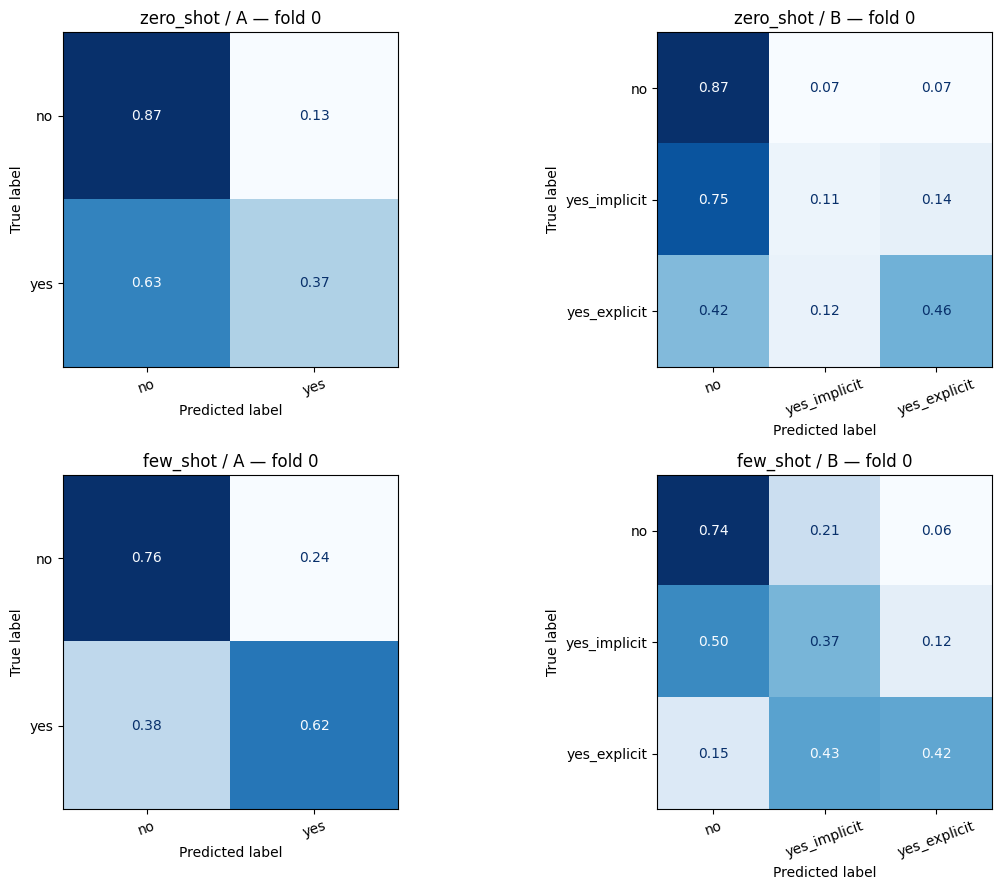

In [5]:
if MODE == "full":
    comparison = compare_baselines(evaluation, llm_table)
    display(comparison[["system", "subtask", "input", "evaluation_scope", "n_eval", "macro_f1"]])
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for ax, run in zip(axes.flat, runs):
        frame = run.frame()
        ConfusionMatrixDisplay.from_predictions(frame.y_true, frame.y_pred, labels=run.labels,
            normalize="true", values_format=".2f", ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{run.mode} / {run.task} — fold 0")
        ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.savefig(ROOT / "outputs/results/llm_confusion_fold0.png", dpi=150)
    plt.show()

## 5. Kết luận (điền sau lượt full)

- Zero-shot và few-shot khác nhau bao nhiêu trên A và B?
- Few-shot có cải thiện F1 implicit không? Có giảm lỗi hate → no không?
- So với TF-IDF và transformer trên đúng fold 0, Qwen đứng ở đâu?
- Ghi rõ giới hạn: model Q4_K_M, prompt tự xây dựng, chỉ fold 0 và input khác baseline.

Đầu ra: `llm_results_fold0.csv`, `llm_comparison_fold0.csv`, hình confusion matrix,
4 file dự đoán và cache. Không gọi đây là điểm test của BTC.